# [Lab Session 4](deconvolution.ipynb)

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.restoration import wiener
from scipy.signal import convolve2d as conv
from scipy.stats import multivariate_normal as multi_normal

np.random.seed(0)

Load the image.

In [3]:
img = plt.imread('data/cells.png')[128:384, 128:384]
plt.imshow(img, 'grey')

**[Task 1.]()** Apply the following PSF to the image and then display it.

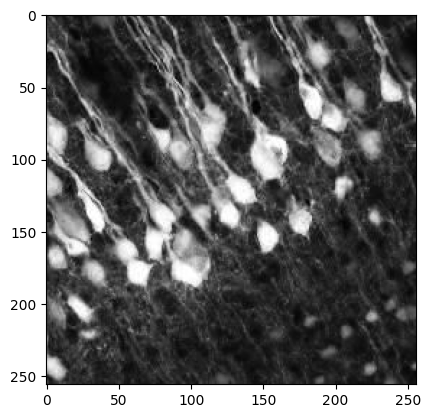

In [4]:
psf_size = 10
psf = np.ones((psf_size, psf_size)) / psf_size ** 2

Text(0.5, 1.0, 'Uniforme PSF')

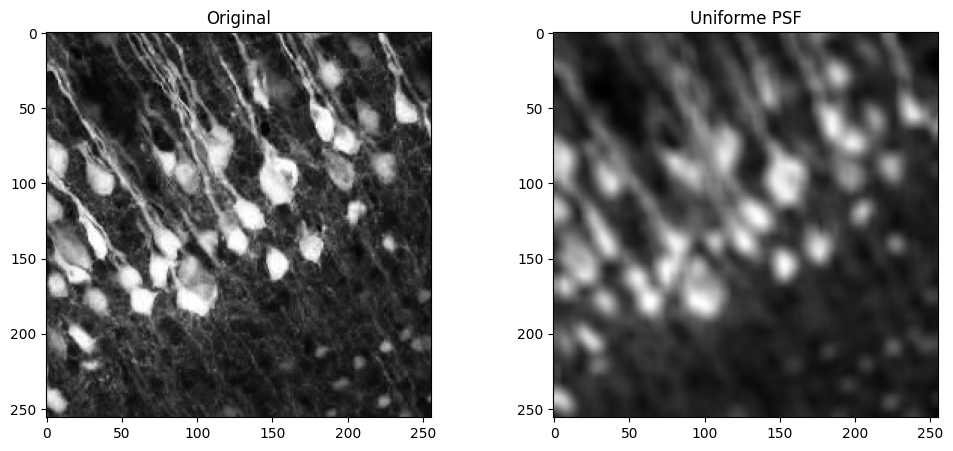

In [5]:
img_psf = conv(img, psf, mode='same', boundary='symm')

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(img, 'gray')
plt.title('Original')

plt.subplot(1, 2, 2)
plt.imshow(img_psf, 'gray')
plt.title('Uniforme PSF')


**[Task 2.]()** Have a look at the Gaussian PSF which is not uniformly distributed. Apply it to the image.

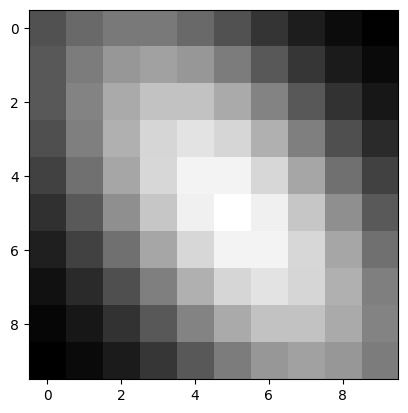

In [6]:
def create_psf(size):
    factor = size * 1.8
    x, y = np.mgrid[0:size:1, 0:size:1]
    pos = np.empty(x.shape + (2,))
    pos[:, :, 0] = x
    pos[:, :, 1] = y
    rv = multi_normal([int(size / 2), (int(size / 2))], [[factor * 1., factor * 1.2], [factor * .5, factor * .7]])
    return rv.pdf(pos)

plt.imshow(create_psf(psf_size), 'gray')

Apply the second psf to the image:

Text(0.5, 1.0, 'Gauß-PSF')

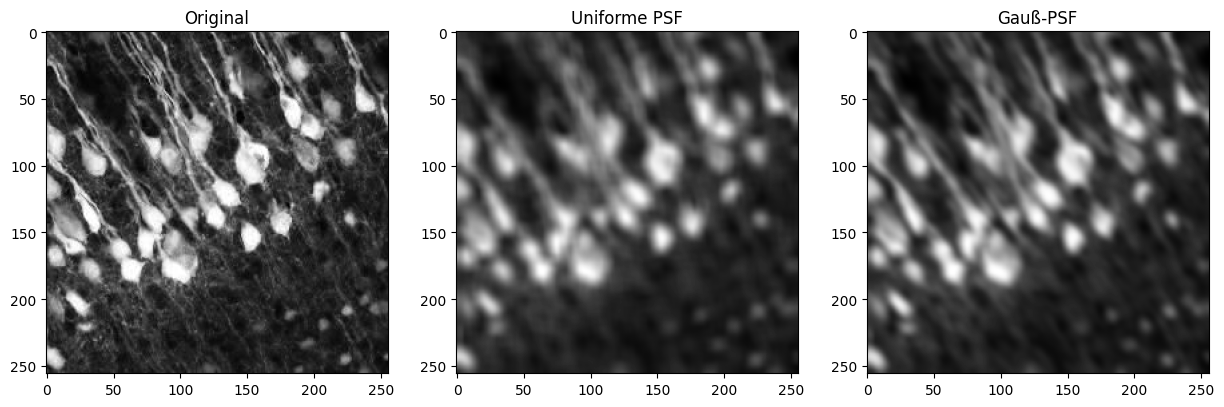

In [7]:
psf_gauss = create_psf(psf_size)
psf_gauss = psf_gauss / psf_gauss.sum()

img_gauss = conv(img, psf_gauss, mode='same', boundary='symm')

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(img, 'gray')
plt.title('Original')
plt.subplot(1, 3, 2)
plt.imshow(img_psf, 'gray')
plt.title('Uniforme PSF')
plt.subplot(1, 3, 3)
plt.imshow(img_gauss, 'gray')
plt.title('Gauß-PSF')


**[Task 3.]()** Implement a reusable function that performs the Richardson-Lucy deconvolution.

In [8]:
def richardson_lucy_deconvolution(image, psf, n_iterations):
    img_deconv = np.full(image.shape, 0.5)
    psf_flipped = np.flip(psf)
    
    for t in range(n_iterations):
        blurred = conv(img_deconv, psf, mode='same', boundary='symm')
        ratio = image / (blurred + 1e-12)
        img_deconv = img_deconv * conv(ratio, psf_flipped, mode='same', boundary='symm')
    
    img_deconv = img_deconv.clip(0,1)
    return img_deconv

**[Task 4.]()** Apply the Richardson-Lucy deconvolution to the blurred image.

In [9]:
deconv_img = richardson_lucy_deconvolution(img_psf, psf, 30)

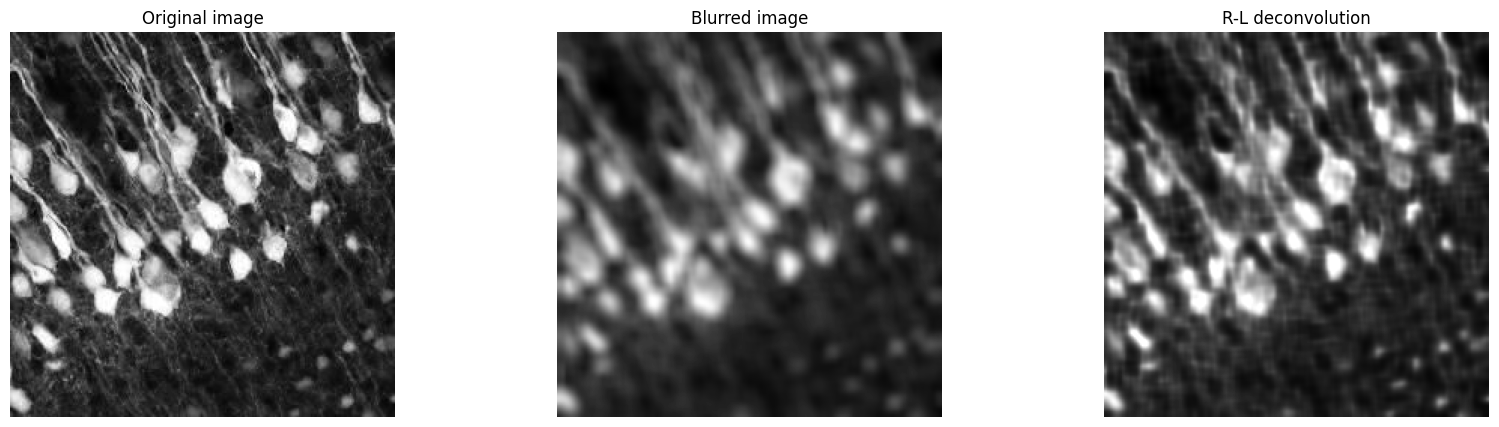

In [10]:
plt.figure(figsize=(20,5))
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')

plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(img_psf, 'gray')
plt.title('Blurred image')

plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(deconv_img, 'gray')
plt.title('R-L deconvolution')
plt.show()

**[Task 5.]()** Add noise to the image, use the R-L deconvolution again.

In [11]:
noise = (np.random.normal(loc=0,size=img.shape))
reduce_factor = 5
noise = noise / reduce_factor

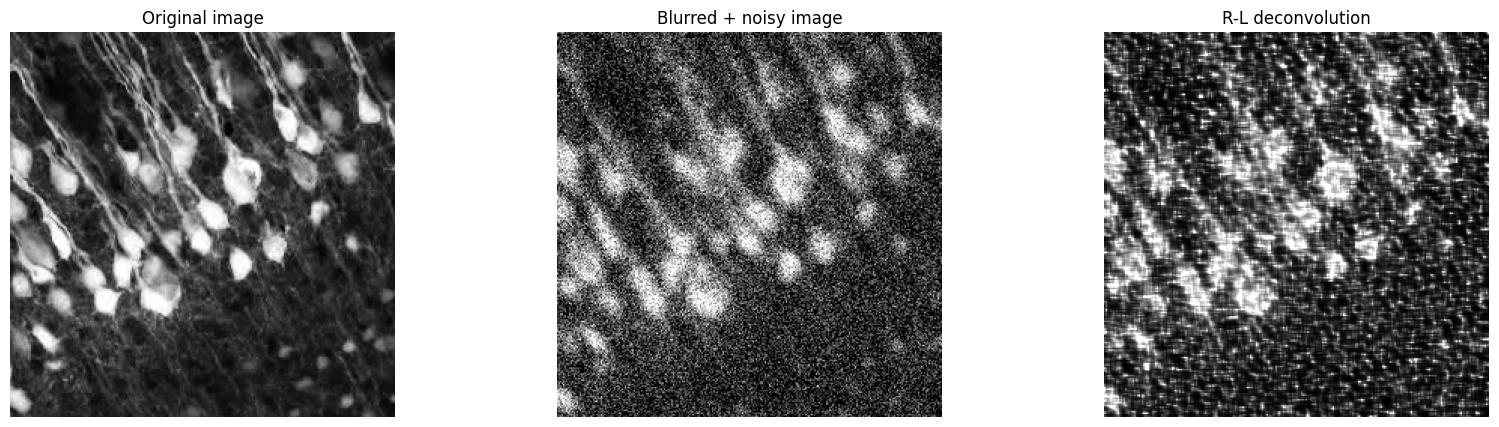

In [12]:
img_noisy = img_gauss + noise
img_noisy = np.clip(img_noisy, 0, 1)

deconv_noisy = richardson_lucy_deconvolution(img_noisy, psf_gauss, 30)

plt.figure(figsize=(20, 5))
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')

plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(img_noisy, 'gray')
plt.title('Blurred + noisy image')

plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(deconv_noisy, 'gray')
plt.title('R-L deconvolution')
plt.show()


**[Task 6.]()** Compare your R-L implementation to a wiener deconvolution.

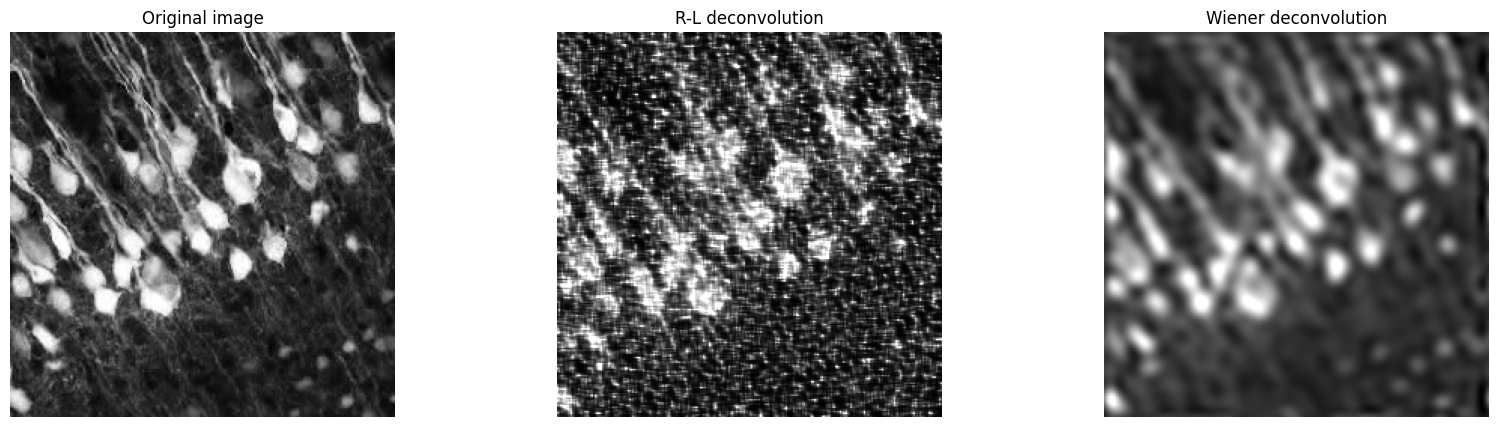

In [13]:
wiener_img = wiener(img_psf, psf, balance=2, clip=True)

plt.figure(figsize=(20, 5))
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')

plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(deconv_noisy, 'gray')
plt.title('R-L deconvolution')

plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(wiener_img, 'gray')
plt.title('Wiener deconvolution')
plt.show()


**[Task 7.]()** Repeat Tasks 4–6 using a smaller value for the size of the PSF.

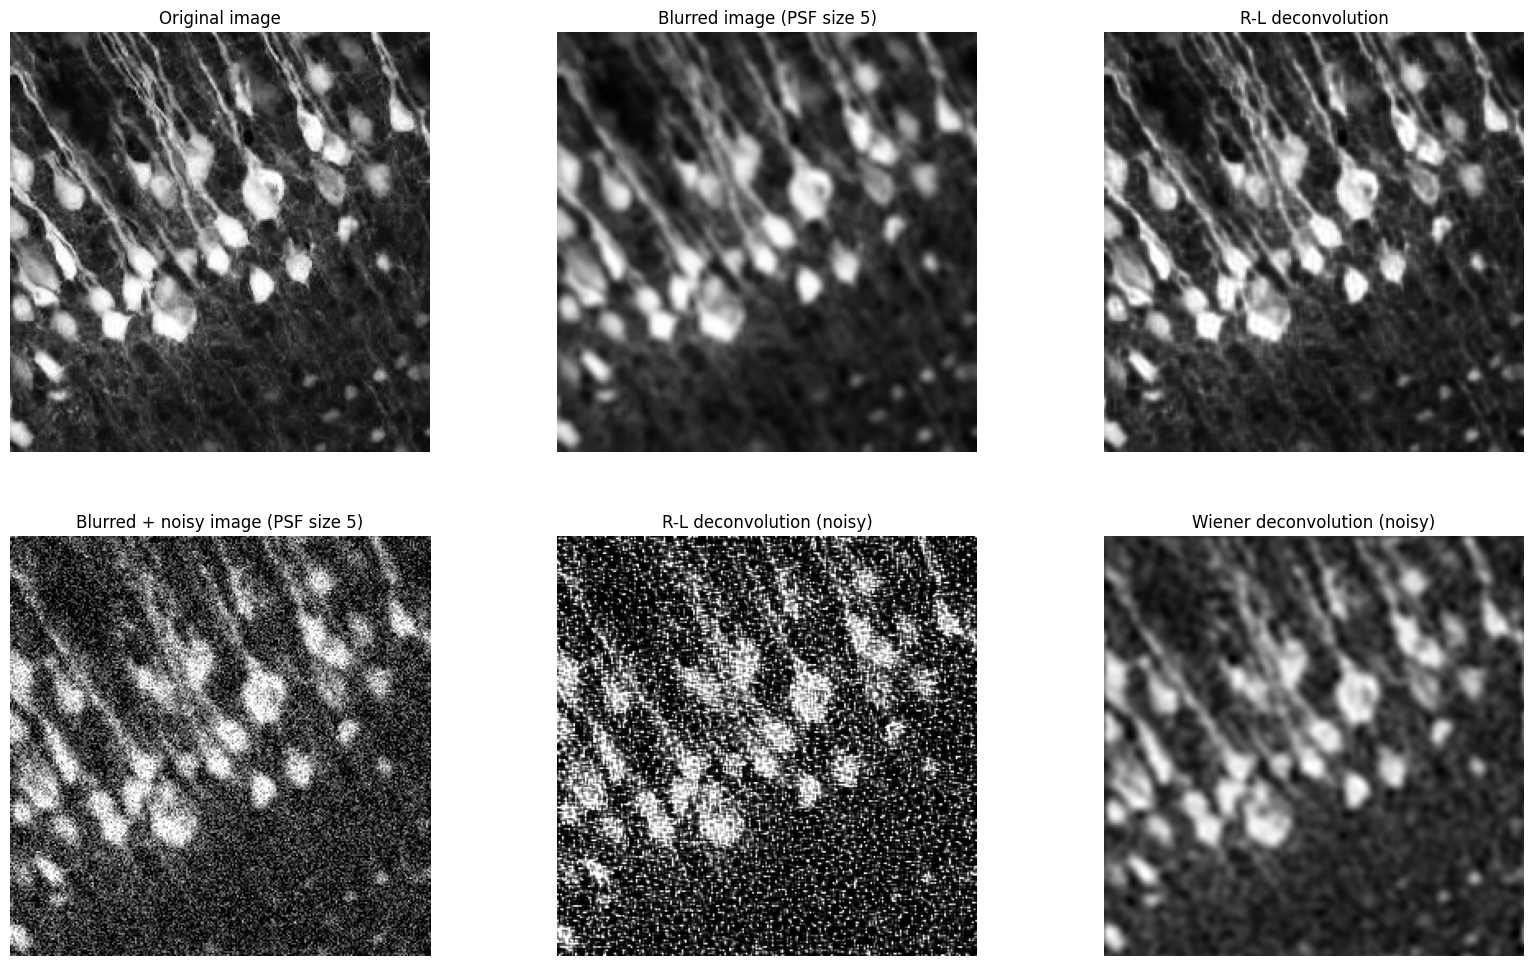

In [ ]:
psf_size_5 = 5

psf_5 = np.ones((psf_size_5, psf_size_5)) / psf_size_5 ** 2 
psf_gauss_5 = create_psf(psf_size_5)
psf_gauss_5 = psf_gauss_5 / psf_gauss_5.sum()    

img_psf_5 = conv(img, psf_5, mode='same', boundary='symm')
img_gauss_5 = conv(img, psf_gauss_5, mode='same', boundary='symm')

deconv_img_5 = richardson_lucy_deconvolution(img_psf_5, psf_5, 30)
img_noisy_5 = np.clip(img_gauss_5 + noise, 0, 1)
deconv_noisy_5 = richardson_lucy_deconvolution(img_noisy_5, psf_gauss_5, 30)
wiener_img_5 = wiener(img_noisy_5, psf_gauss_5, balance=2, clip=True)

plt.figure(figsize=(20, 12))

plt.subplot(2, 3, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')

plt.subplot(2, 3, 2)
plt.axis('off')
plt.imshow(img_psf_5, 'gray')
plt.title('Blurred image (PSF size 5)')

plt.subplot(2, 3, 3)
plt.axis('off')
plt.imshow(deconv_img_5, 'gray')
plt.title('R-L deconvolution')

plt.subplot(2, 3, 4)
plt.axis('off')
plt.imshow(img_noisy_5, 'gray')
plt.title('Blurred + noisy image (PSF size 5)')

plt.subplot(2, 3, 5)
plt.axis('off')
plt.imshow(deconv_noisy_5, 'gray')
plt.title('R-L deconvolution (noisy)')

plt.subplot(2, 3, 6)
plt.axis('off')
plt.imshow(wiener_img_5, 'gray')
plt.title('Wiener deconvolution (noisy)')

plt.show()


**[Task 8.]()** Use a wrong PSF to restore the image

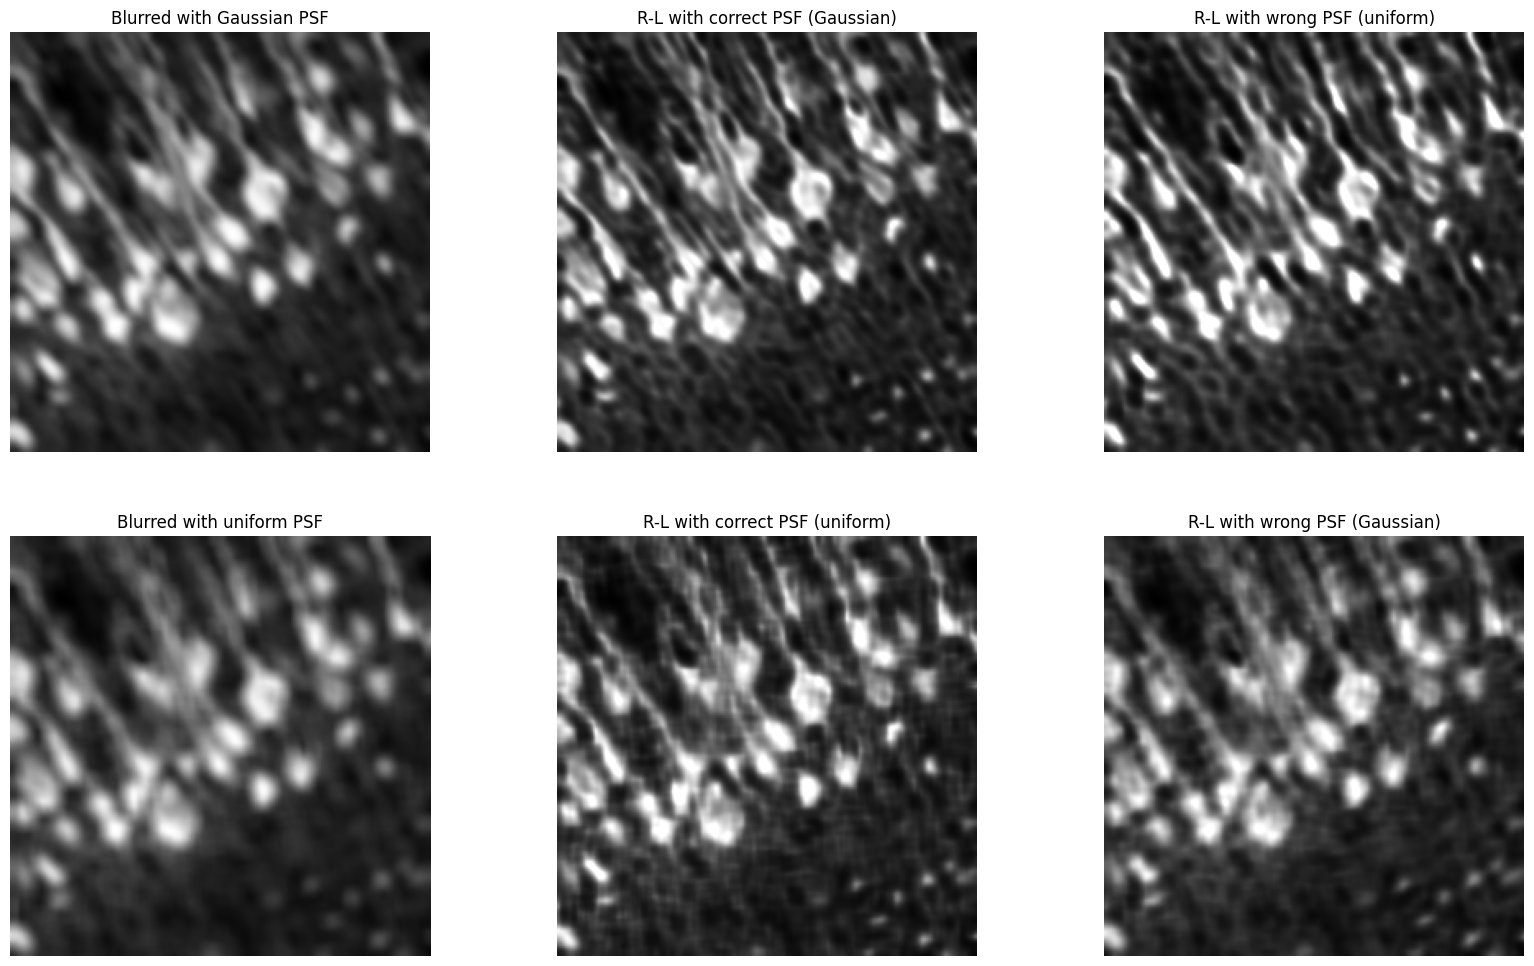

In [ ]:

wrong_gauss = richardson_lucy_deconvolution(img_gauss, psf, 30)   
wrong_uniform = richardson_lucy_deconvolution(img_psf, psf_gauss, 30) 

right_gauss = richardson_lucy_deconvolution(img_gauss, psf_gauss, 30)
right_uniform = richardson_lucy_deconvolution(img_psf, psf, 30)

plt.figure(figsize=(20, 12))
plt.subplot(2, 3, 1)
plt.axis('off')
plt.imshow(img_gauss, 'gray')
plt.title('Blurred with Gaussian PSF')

plt.subplot(2, 3, 2)
plt.axis('off')
plt.imshow(right_gauss, 'gray')
plt.title('R-L with correct PSF (Gaussian)')

plt.subplot(2, 3, 3)
plt.axis('off')
plt.imshow(wrong_gauss, 'gray')
plt.title('R-L with wrong PSF (uniform)')

# Zeile 2: Bild mit uniformer PSF verwischt
plt.subplot(2, 3, 4)
plt.axis('off')
plt.imshow(img_psf, 'gray')
plt.title('Blurred with uniform PSF')

plt.subplot(2, 3, 5)
plt.axis('off')
plt.imshow(right_uniform, 'gray')
plt.title('R-L with correct PSF (uniform)')

plt.subplot(2, 3, 6)
plt.axis('off')
plt.imshow(wrong_uniform, 'gray')
plt.title('R-L with wrong PSF (Gaussian)')

plt.show()
